# Double Tube-Preserving Regularization (DTR): supplementary material

Companion to `01_DTR_main_paper.ipynb`. It implements and numerically checks the supplementary material of NEUCOM-D-26-21531 (*Supp_DTR_20260922.pdf*).

| Supplement | Notebook section |
|---|---|
| §1 Notations, t-SVD, tubal rank, TNN (Defs. 1–3) | 2 |
| §2.1 Lemma 1 (WNNM) and the proof of Theorem 1 (T2NN proximal operator) | 3 |
| §2.2 Lemma 2, Lemma 3 and Theorem 2 (convergence of Algorithm 1) | 4 |
| §2.3 GDTR: gradient tensor (main Def. 10), t-CTV (Eq. 20), TGTNN (Def. 11), Algorithm 2 | 5 |
| §3 Additional experiments (Supp. Fig. 1), plus the t-CTV / GDTR columns of main Tabs. 2, 3 and 5 | 6 |
| Summary | 7 |

The core DTR code is repeated from notebook 01 so this notebook runs on its own. With the same seeds, the corrupted images and videos are identical to those in notebook 01, so the TRPCA and DTR numbers can be compared directly.

**Methods.** RPCA, TRPCA, DTR, t-CTV and GDTR are implemented. t-CTV is Algorithm 2 with all weights fixed to 1, which is exactly the t-CTV-RPCA model of Wang et al. SNN and ETRPCA, which also appear in Supp. Fig. 1, are not reimplemented.

**Runtime.** About 25 minutes on a 16-core machine with the defaults (`N_SUPP_IMAGES = 25`, 100 video frames).

## 1. Setup

In [1]:
import os
# The per-slice SVDs here are small, so single-threaded BLAS is as fast or faster;
# experiments are parallelised across worker processes instead (see run_parallel).
# This must run before numpy is imported - restart the kernel if numpy was already loaded.
for _v in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_v, '1')

import tarfile
import time
import urllib.request
import warnings
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path('data')
N_JOBS = max(1, min(12, (os.cpu_count() or 2) - 2))   # worker processes for independent runs
SEED = 0
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray', 'axes.grid': False})
pd.set_option('display.precision', 2)
print(f'numpy {np.__version__} | N_JOBS = {N_JOBS}')

numpy 2.4.4 | N_JOBS = 12


In [2]:
BSDS_URL = 'https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/BSR/BSR_bsds500.tgz'
YUV_URL = 'https://media.xiph.org/video/derf/y4m/{}_qcif.y4m'


def ensure_bsds(root=DATA_DIR):
    """Download BSDS500 (~70 MB) once; keeps only the 500 JPEGs in data/BSDS500/{train,val,test}."""
    out = root / 'BSDS500'
    if out.exists():
        return out
    root.mkdir(parents=True, exist_ok=True)
    tgz = root / 'BSR_bsds500.tgz'
    print('downloading BSDS500 ...')
    urllib.request.urlretrieve(BSDS_URL, tgz)
    prefix = 'BSR/BSDS500/data/images/'
    with tarfile.open(tgz) as tf:
        for m in tf.getmembers():
            if m.isfile() and m.name.startswith(prefix) and m.name.endswith('.jpg'):
                m.name = m.name[len(prefix):]
                tf.extract(m, out, filter='data')
    tgz.unlink()
    return out


def ensure_yuv(name, root=DATA_DIR):
    """Download a QCIF (176x144) test sequence from the Xiph derf collection."""
    path = root / 'yuv' / f'{name}_qcif.y4m'
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print(f'downloading {name} ...')
        urllib.request.urlretrieve(YUV_URL.format(name), path)
    return path


def read_y4m(path, n_frames=None, rgb=False):
    """Minimal YUV4MPEG2 4:2:0 reader -> floats in [0, 1].
    Returns the luma as (H, W, T), or BT.601 RGB as (H, W, 3, T) if rgb=True."""
    data = Path(path).read_bytes()
    end = data.index(b'\n')
    hdr = {tok[:1]: tok[1:] for tok in data[:end].split()[1:]}
    W, H = int(hdr[b'W']), int(hdr[b'H'])
    ysz, csz = W * H, (W // 2) * (H // 2)
    pos, frames = end + 1, []
    while pos < len(data) and (n_frames is None or len(frames) < n_frames):
        pos = data.index(b'\n', pos) + 1                          # skip the 'FRAME' line
        Y = np.frombuffer(data, np.uint8, ysz, pos).reshape(H, W).astype(float)
        if rgb:
            U, V = (np.kron(np.frombuffer(data, np.uint8, csz, pos + ysz + i * csz)
                            .reshape(H // 2, W // 2).astype(float), np.ones((2, 2))) - 128 for i in (0, 1))
            Yl = 1.164 * (Y - 16)
            rgb_frame = np.stack([Yl + 1.596 * V, Yl - 0.392 * U - 0.813 * V, Yl + 2.017 * U], axis=-1)
            frames.append(np.clip(rgb_frame / 255, 0, 1))
        else:
            frames.append(Y / 255)
        pos += ysz + 2 * csz
    return np.stack(frames, axis=-1)


def load_image(path):
    return np.asarray(Image.open(path).convert('RGB'), dtype=np.float64) / 255.0


def psnr(x, ref):
    """PSNR (dB) over the whole tensor for data in [0, 1]; the estimate is clipped to [0, 1] first."""
    return 10 * np.log10(1.0 / np.mean((np.clip(x, 0, 1) - ref) ** 2))


def tube_corrupt(X, ratio, rng):
    """Tube-wise corruption used throughout Sec. 4: a fraction `ratio` of the (i, j) positions is
    replaced by random values from [0, 255] (scaled to [0, 1]) in *every* frontal slice."""
    d1, d2, d3 = X.shape
    idx = rng.choice(d1 * d2, int(round(ratio * d1 * d2)), replace=False)
    Y = X.reshape(d1 * d2, d3).copy()
    Y[idx] = rng.integers(0, 256, (idx.size, d3)) / 255.0
    mask = np.zeros(d1 * d2, bool)
    mask[idx] = True
    return Y.reshape(d1, d2, d3), mask.reshape(d1, d2)


def run_parallel(fn, jobs, n_jobs=None):
    """Map fn over jobs in forked worker processes (order preserved); plain loop if fork is unavailable."""
    n_jobs = N_JOBS if n_jobs is None else n_jobs
    if n_jobs > 1 and len(jobs) > 1 and 'fork' in mp.get_all_start_methods():
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', DeprecationWarning)   # "process is multi-threaded, fork() ..."
            with ProcessPoolExecutor(min(n_jobs, len(jobs)), mp_context=mp.get_context('fork')) as ex:
                return list(ex.map(fn, jobs))
    return [fn(j) for j in jobs]


bsds = ensure_bsds()
TEST_FILES = sorted((bsds / 'test').glob('*.jpg'))
EXAMPLES = TEST_FILES[:6]          # example images for Fig. 6 / Tab. 2 (the paper does not name its six)
print('BSDS500 images:', {s: len(list((bsds / s).glob('*.jpg'))) for s in ('train', 'val', 'test')})

BSDS500 images: {'train': 200, 'val': 100, 'test': 200}


## 2. Preliminaries (supplement §1)

The t-SVD, tubal rank and TNN are as in notebook 01, §2. All we need here is the unfolding singular value matrix $\Sigma^+$ and TNN, together with the identity $\|\bar{\mathcal L}\|_F^2=d_3\|\mathcal L\|_F^2$. The proof of Theorem 1 uses that identity to split the problem into $d_3$ independent matrix problems.

In [3]:
def svd_unfold(X):
    """Def. 7 - unfolding singular value matrix Sigma+ (d x d3): column k holds the singular
    values of the k-th Fourier-domain frontal slice, so row l is the l-th singular tube."""
    Xf = np.fft.fft(X, axis=2)
    return np.linalg.svd(np.moveaxis(Xf, 2, 0), compute_uv=False).T


def tnn(X):
    """Def. 6 - tensor nuclear norm (1/d3) sum_k ||Xbar^(k)||_* = (1/d3) ||Sigma+||_1."""
    return svd_unfold(X).sum() / X.shape[2]

In [4]:
def structure_fn(x, tau):
    """Structure function f(x) = 1 / (1 + x / tau) shared by T2NN (f_L) and T2L1 (f_E)."""
    return 1.0 / (1.0 + x / tau)


def structure_weights(tube_norms, gamma):
    """Adaptive weights f(||tube||_2) with tau = gamma * mean(||tube||_2) (Sec. 3.3, Parameter Analysis).
    Before any tube is nonzero (e.g. E = 0 in the first iterations) tau = 0 and all weights are 1."""
    tau = gamma * tube_norms.mean()
    return np.ones_like(tube_norms) if tau == 0 else structure_fn(tube_norms, tau)


def t2nn_prox(M, tau, w):
    """Proximal operator of the T2NN, Eq. (13): U * ifft(P_{tau w}(S_bar), [], 3) * V^*.
    Each Fourier slice is shrunk by (S_ll - tau * w_l)_+. Only the first floor(d3/2)+1 slices are
    decomposed; the rest follow from conjugate symmetry of the DFT of a real tensor.
    Returns the minimiser L and its unfolding singular value matrix Sigma+ (d x d3)."""
    d1, d2, d3 = M.shape
    Mf = np.fft.fft(M, axis=2)
    half = d3 // 2 + 1
    U, s, Vh = np.linalg.svd(np.moveaxis(Mf[:, :, :half], 2, 0), full_matrices=False)
    s = np.maximum(s - tau * w[None, :], 0.0)
    Lf = np.empty_like(Mf)
    Lf[:, :, :half] = np.moveaxis((U * s[:, None, :]) @ Vh, 0, 2)
    Sig = np.empty((s.shape[1], d3))
    Sig[:, :half] = s.T
    if d3 > 1:
        Lf[:, :, half:] = np.conj(Lf[:, :, 1:d3 - half + 1][:, :, ::-1])
        Sig[:, half:] = Sig[:, 1:d3 - half + 1][:, ::-1]
    return np.real(np.fft.ifft(Lf, axis=2)), Sig


def t2l1_prox(K, thr):
    """Tensor soft-thresholding Q(K, thr): sign(K_ijk) (|K_ijk| - thr_ij)_+, one threshold per tube."""
    return np.sign(K) * np.maximum(np.abs(K) - thr[:, :, None], 0.0)


def dtr(X, lam=None, gamma_L=3.0, gamma_E=1e3, tube_L=True, tube_E=True,
        mu=1e-2, rho=1.1, mu_max=1e10, tol=1e-6, max_iter=500, history=False):
    """Algorithm 1 - TRPCA via Double Tube-preserving Regularization.

    tube_L / tube_E switch the adaptive weights of T2NN / T2L1 on. With both off the weights stay
    at 1 and this is exactly TRPCA (TNN + l1, Lu et al.); one on gives the ablation variants
    DTR-L / DTR-E of Tab. 6. mu_max caps the penalty as in the reference TRPCA code (the paper does
    not cap it). Returns (L, E) or (L, E, history DataFrame)."""
    d1, d2, d3 = X.shape
    lam = 1.0 / np.sqrt(d3 * max(d1, d2)) if lam is None else lam
    L, E, N = np.zeros_like(X), np.zeros_like(X), np.zeros_like(X)
    w, W = np.ones(min(d1, d2)), np.ones((d1, d2))                # w^0 = 1_d, W^0 = 1_{d1 x d2}
    hist = []
    for t in range(max_iter):
        L_new, Sig = t2nn_prox(X - E - N / mu, 1.0 / mu, w)       # Step 1: Eqs. (12)-(13), tau = 1/mu
        E_new = t2l1_prox(X - L_new - N / mu, lam / mu * W)       # Step 2: Eqs. (15)-(16)
        tubes_L, tubes_E = np.linalg.norm(Sig, axis=1), np.linalg.norm(E_new, axis=2)
        if tube_L:
            w = structure_weights(tubes_L, gamma_L)               # Step 3: Eq. (17)
        if tube_E:
            W = structure_weights(tubes_E, gamma_E)               #         Eq. (18)
        R = L_new + E_new - X
        N = N + mu * R                                            # Step 4
        dL, dE, err = np.abs(L_new - L).max(), np.abs(E_new - E).max(), np.abs(R).max()
        if history:
            hist.append(dict(
                iter=t + 1, mu=mu, dL=dL, dE=dE, err=err,
                dL_F=np.linalg.norm(L_new - L), dE_F=np.linalg.norm(E_new - E), err_F=np.linalg.norm(R),
                N_F=np.linalg.norm(N), L_F=np.linalg.norm(L_new), E_F=np.linalg.norm(E_new),
                T2NN=(structure_weights(tubes_L, gamma_L) * Sig.sum(axis=1)).sum() / d3,
                T2L1=(structure_weights(tubes_E, gamma_E) * np.abs(E_new).sum(axis=2)).sum(),
                w_min=w.min(), w_max=w.max(), W_min=W.min(), W_max=W.max()))
        L, E = L_new, E_new
        mu = min(rho * mu, mu_max)                                # Step 5
        if max(dL, dE, err) < tol:                                # Step 6
            break
    return (L, E, pd.DataFrame(hist).set_index('iter')) if history else (L, E)


VARIANTS = {'TRPCA': dict(tube_L=False, tube_E=False),
            'DTR-L': dict(tube_E=False),
            'DTR-E': dict(tube_L=False),
            'DTR': {}}

In [5]:
rng = np.random.default_rng(SEED)
Lt = rng.standard_normal((7, 5, 6))
print('||Lbar||_F^2 - d3 ||L||_F^2 =', np.linalg.norm(np.fft.fft(Lt, axis=2)) ** 2 - 6 * np.linalg.norm(Lt) ** 2)

||Lbar||_F^2 - d3 ||L||_F^2 = -2.2737367544323206e-13


## 3. Theorem 1: the T2NN proximal operator (supplement §2.1)

**Lemma 1 (WNNM, Gu et al.).** If $0\le w_1\le\dots\le w_d$, the minimiser of $\tfrac12\|L-M\|_F^2+\sum_l w_l\sigma_l(L)$ is $U\,(\Sigma-\mathrm{diag}(w))_+V^\top$.

**Theorem 1.** For fixed nondecreasing weights, $\mathrm{prox}(\mathcal M)=\mathcal U*\mathrm{ifft}(P_{\tau w}(\bar{\mathcal S}))*\mathcal V^*$ minimises $\tfrac12\|\mathcal L-\mathcal M\|_F^2+\tau\|\mathcal L\|_{T,*}$.

*Proof idea.* By Parseval, the problem is $\frac1{2d_3}\sum_k\|\bar{\mathcal L}^{(k)}-\bar{\mathcal M}^{(k)}\|_F^2+\frac{\tau}{d_3}\sum_k\|\bar{\mathcal L}^{(k)}\|_{w,*}$, which splits into $d_3$ WNNM problems, one per slice. Lemma 1 solves each of them.

In Algorithm 1 the weights are frozen inside each subproblem, so the theorem is about a weighted TNN with fixed $w$. The problem is **nonconvex**: weights that grow with $l$ penalise small singular values more. We therefore test optimality numerically:
- random perturbations around the closed form;
- derivative-free local searches (Powell) from many random starts.

Any point with a lower objective than the closed form would disprove the claim.

In [6]:
from scipy.optimize import minimize


def wnnm_obj(Lvec, M, w):
    """Lemma 1 objective, weights attached to the *sorted* singular values of L."""
    return 0.5 * np.sum((Lvec.reshape(M.shape) - M) ** 2) + np.sum(w * np.linalg.svd(Lvec.reshape(M.shape), compute_uv=False))


def wnnm_closed(M, w):
    U, s, Vh = np.linalg.svd(M, full_matrices=False)
    return (U * np.maximum(s - w, 0.0)) @ Vh


def thm1_obj(Lvec, M, tau, w):
    """Theorem 1 objective 1/2||L - M||_F^2 + tau/d3 sum_l w_l sum_k sigma_l(Lbar^(k)), weights frozen."""
    L = Lvec.reshape(M.shape)
    return 0.5 * np.sum((L - M) ** 2) + tau * (w * svd_unfold(L).sum(axis=1)).sum() / M.shape[2]


def optimality_test(obj, x_star, args, n_pert=4000, n_starts=20, seed=0):
    """Smallest objective found by perturbation / Powell restarts, minus the closed-form objective."""
    rng = np.random.default_rng(seed)
    f_star = obj(x_star, *args)
    pert = min(obj(x_star + s * rng.standard_normal(x_star.size), *args)
               for s in (1e-4, 1e-3, 1e-2, 1e-1, 1.0) for _ in range(n_pert // 5))
    local = min(minimize(obj, 2 * rng.standard_normal(x_star.size), args=args, method='Powell',
                         options=dict(maxiter=50000, xtol=1e-10, ftol=1e-13)).fun for _ in range(n_starts))
    return dict(closed_form=f_star, best_perturbation_minus_closed=pert - f_star, best_powell_minus_closed=local - f_star)


rng = np.random.default_rng(SEED)
rows = {}
# Lemma 1, matrix 5 x 4, nondecreasing weights
Mm = 2 * rng.standard_normal((5, 4))
w_inc = np.sort(rng.uniform(0.2, 2.5, 4))
rows['Lemma 1, w nondecreasing'] = optimality_test(wnnm_obj, wnnm_closed(Mm, w_inc).ravel(), (Mm, w_inc))

# Theorem 1, tensor 4 x 3 x 3, weights from the structure function (automatically nondecreasing)
Mt = 2 * rng.standard_normal((4, 3, 3))
tau = 0.8
w_t = structure_weights(np.linalg.norm(svd_unfold(Mt), axis=1), 3.0)
assert np.all(np.diff(w_t) >= 0), 'structure-function weights must be nondecreasing'
rows['Theorem 1, w = f_L(tube norms)'] = optimality_test(thm1_obj, t2nn_prox(Mt, tau, w_t)[0].ravel(), (Mt, tau, w_t))

# The ordering assumption matters: decreasing weights can reorder the shrunk singular values
Md, w_dec = np.diag([3.0, 2.5]), np.array([2.0, 0.0])
rows['Lemma 1, w decreasing (assumption violated)'] = optimality_test(wnnm_obj, wnnm_closed(Md, w_dec).ravel(), (Md, w_dec))
display(pd.DataFrame(rows).T)
print('weights used in Theorem 1 test:', np.round(w_t, 4))

,closed_form,best_perturbation_minus_closed,best_powell_minus_closed
"Lemma 1, w nondecreasing",6.78,5.91e-06,1.07e-01
"Theorem 1, w = f_L(tube norms)",9.36,7.94e-08,7.11e-15
"Lemma 1, w decreasing (assumption violated)",7.00,-2.05e+00,-2.44e+00


weights used in Theorem 1 test: [0.6514 0.7847 0.84  ]


With nondecreasing weights, neither the perturbations nor the Powell restarts beat the closed form: every difference is $\ge0$. Powell often stops in worse local minima because the problem is nonconvex. With decreasing weights, both searches find strictly better points. For example, $M=\mathrm{diag}(3,2.5)$ and $w=(2,0)$ give a closed form of $\mathrm{diag}(1,2.5)$ with objective 7, while $\mathrm{diag}(1.75,1.75)$ reaches 4.56. So the ordering condition in Theorem 1 is necessary, and the structure function $f_L$ satisfies it automatically.

## 4. Convergence of Algorithm 1 (supplement §2.2)

- **Lemma 2.** $\{\mathcal N^t\}$, $\{w^t\}$ and $\{W^t\}$ are bounded. The weights lie in $(0,1]$. The supplement bounds $\|\mathcal N^{t+1}\|_F\le\lambda d_1d_2d_3$. The same argument gives the tighter bound $\lambda\|W\|_F\sqrt{d_3}\le\lambda\sqrt{d_1d_2d_3}$, because $|\mathcal Q(\mathcal K,\theta)-\mathcal K|\le\theta$ entry-wise.
- **Lemma 3.** $\{\mathcal L^t\}$ and $\{\mathcal E^t\}$ are bounded, via boundedness of the Lagrangian and of $\|\mathcal L^t\|_{T,*}+\|\mathcal E^t\|_{T,1}$.
- **Theorem 2.** $\|\mathcal L^t+\mathcal E^t-\mathcal X\|_F\to0$, $\|\mathcal L^{t+1}-\mathcal L^t\|_F\to0$ and $\|\mathcal E^{t+1}-\mathcal E^t\|_F\to0$.

The proof needs $\sum_t\mu_t/\mu_{t-1}^2<\infty$, which holds for $\mu_t=\rho^t\mu_0$ with no cap. We therefore run Algorithm 1 with `mu_max=inf` on a corrupted BSD image for up to 400 iterations, record every quantity in the lemmas, and do the same for TRPCA as a reference.

{'TRPCA': '233 iterations, PSNR 35.45 dB', 'DTR': '233 iterations, PSNR 37.19 dB'}


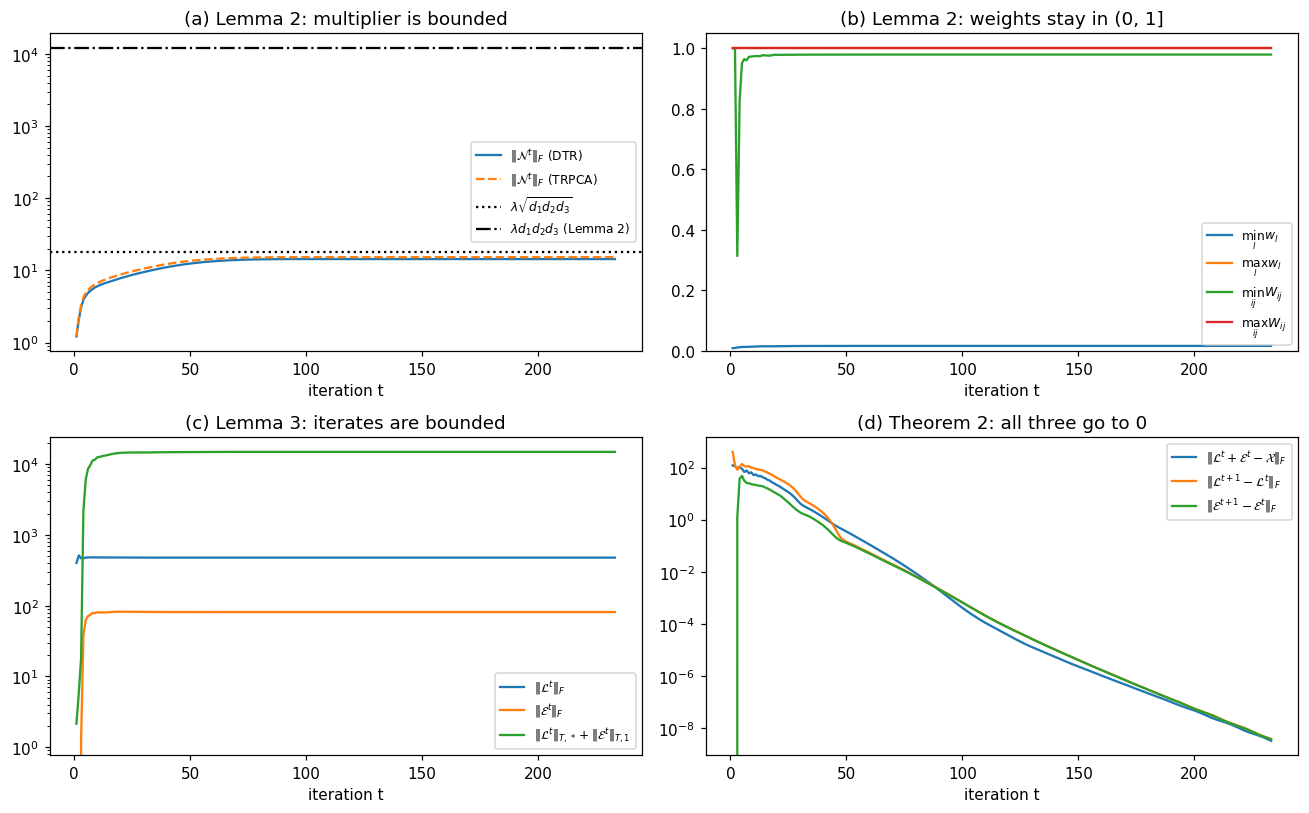

sum_t mu_t / mu_(t-1)^2 over the run = 1210.000 (converges: geometric series)
max ||N||_F = 14.344 <= lambda*sqrt(d1d2d3) = 17.916 <= lambda*d1d2d3 = 12193.8


,err_F,dL_F,dE_F
iter,,,
1,1.21e+02,4.01e+02,0.00e+00
50,3.50e-01,1.42e-01,1.27e-01
100,4.06e-04,6.58e-04,6.47e-04
200,4.62e-08,5.48e-08,5.36e-08
233,3.19e-09,3.73e-09,3.62e-09


In [7]:
rng = np.random.default_rng(SEED)
ref0 = load_image(EXAMPLES[0])
X0n, _ = tube_corrupt(ref0, 0.10, rng)
d1, d2, d3 = X0n.shape
lam0 = 1 / np.sqrt(d3 * max(d1, d2))


def conv_job(name):
    L, E, h = dtr(X0n, mu_max=np.inf, tol=1e-10, max_iter=400, history=True, **VARIANTS[name])
    return name, h, psnr(L, ref0)


conv = dict((nm, (h, p)) for nm, h, p in run_parallel(conv_job, ['TRPCA', 'DTR']))
h = conv['DTR'][0]
print({nm: f'{len(hh)} iterations, PSNR {p:.2f} dB' for nm, (hh, p) in conv.items()})

fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
ax[0, 0].semilogy(h.index, h.N_F, label='$\\|\\mathcal{N}^t\\|_F$ (DTR)')
ax[0, 0].semilogy(conv['TRPCA'][0].index, conv['TRPCA'][0].N_F, '--', label='$\\|\\mathcal{N}^t\\|_F$ (TRPCA)')
ax[0, 0].axhline(lam0 * np.sqrt(d1 * d2 * d3), color='k', ls=':', label='$\\lambda\\sqrt{d_1d_2d_3}$')
ax[0, 0].axhline(lam0 * d1 * d2 * d3, color='k', ls='-.', label='$\\lambda d_1d_2d_3$ (Lemma 2)')
ax[0, 0].set_title('(a) Lemma 2: multiplier is bounded'); ax[0, 0].legend(fontsize=8)
for col, lab in (('w_min', '$\\min_l w_l$'), ('w_max', '$\\max_l w_l$'), ('W_min', '$\\min_{ij} W_{ij}$'), ('W_max', '$\\max_{ij} W_{ij}$')):
    ax[0, 1].plot(h.index, h[col], label=lab)
ax[0, 1].set(title='(b) Lemma 2: weights stay in (0, 1]', ylim=(0, 1.05)); ax[0, 1].legend(fontsize=8)
ax[1, 0].plot(h.index, h.L_F, label='$\\|\\mathcal{L}^t\\|_F$'); ax[1, 0].plot(h.index, h.E_F, label='$\\|\\mathcal{E}^t\\|_F$')
ax[1, 0].plot(h.index, h.T2NN + h.T2L1, label='$\\|\\mathcal{L}^t\\|_{T,*}+\\|\\mathcal{E}^t\\|_{T,1}$')
ax[1, 0].set(title='(c) Lemma 3: iterates are bounded', yscale='log'); ax[1, 0].legend(fontsize=8)
for col, lab in (('err_F', '$\\|\\mathcal{L}^t+\\mathcal{E}^t-\\mathcal{X}\\|_F$'), ('dL_F', '$\\|\\mathcal{L}^{t+1}-\\mathcal{L}^t\\|_F$'),
                 ('dE_F', '$\\|\\mathcal{E}^{t+1}-\\mathcal{E}^t\\|_F$')):
    ax[1, 1].semilogy(h.index, h[col], label=lab)
ax[1, 1].set_title('(d) Theorem 2: all three go to 0'); ax[1, 1].legend(fontsize=8)
for a in ax.ravel():
    a.set_xlabel('iteration t')
plt.tight_layout(); plt.show()

mu_t = h.mu.values
print(f'sum_t mu_t / mu_(t-1)^2 over the run = {np.sum(mu_t[1:] / mu_t[:-1] ** 2):.3f} (converges: geometric series)')
print(f'max ||N||_F = {h.N_F.max():.3f} <= lambda*sqrt(d1d2d3) = {lam0 * np.sqrt(d1 * d2 * d3):.3f}'
      f' <= lambda*d1d2d3 = {lam0 * d1 * d2 * d3:.1f}')
display(h[['err_F', 'dL_F', 'dE_F']].iloc[[i for i in (0, 49, 99, 199) if i < len(h) - 1] + [-1]])

## 5. GDTR: Gradient DTR (main §3.5, supplement §2.3)

**Def. 10.** The mode-$m$ gradient is $\mathcal G_m=\nabla_m(\mathcal X)=\mathcal X\times_m D_{d_m}$, where $D_{d_m}$ is the row-circulant matrix of $(-1,1,0,\dots,0)$, i.e. a circular forward difference.

**t-CTV (Eq. 20)** is $\frac1{|\Gamma|}\sum_{m\in\Gamma}\|\mathcal G_m\|_*$. **TGTNN (Def. 11)** replaces TNN with T2NN: $\frac1{|\Gamma|}\sum_{m\in\Gamma}\|\mathcal G_m\|_{T,*}$. GDTR is

$$\min\ \|\mathcal L\|_{TG,*}+\lambda\|\mathcal E\|_{T,1}\quad\text{s.t.}\quad\mathcal X=\mathcal L+\mathcal E.$$

$\Gamma$ lists the smooth modes: $\{1,2\}$ for color images and $\{1,2,3\}$ for videos.

The ADMM of Algorithm 2 splits $\mathcal G_m=\nabla_m(\mathcal L)$. The $\mathcal L$-subproblem (Eq. 26) is the linear system $(\mathcal I+\sum_m\nabla_m^\top\nabla_m)\mathcal L=\text{rhs}$. Circular differences are diagonalised by the 3-D FFT, which gives Eq. (27).

The first cell checks the operator identities this relies on.

In [8]:
def grad(X, m):
    """Def. 10 - circular forward difference along mode m: (X x_m D)[i] = X[i+1] - X[i]."""
    return np.roll(X, -1, axis=m) - X


def grad_T(G, m):
    """Adjoint of grad along mode m: G[i-1] - G[i]."""
    return np.roll(G, 1, axis=m) - G


def diff_eig(shape, m):
    """|F(D_m)|^2 broadcast over the tensor: eigenvalues 2 - 2cos(2 pi k / d_m) of grad_T(grad(.)) on mode m."""
    n = shape[m]
    return (2 - 2 * np.cos(2 * np.pi * np.arange(n) / n)).reshape([n if a == m else 1 for a in range(3)])


def mode_product(X, D, m):
    """X x_m D."""
    return np.moveaxis(np.tensordot(D, X, axes=(1, m)), 0, m)


def circ_diff_matrix(n):
    """Row circulant matrix of (-1, 1, 0, ..., 0)."""
    return np.stack([np.roll(np.r_[-1.0, 1.0, np.zeros(n - 2)], i) for i in range(n)])


rng = np.random.default_rng(SEED)
Xg, Gg = rng.standard_normal((6, 5, 4)), rng.standard_normal((6, 5, 4))
checks = {}
for m in range(3):
    D = circ_diff_matrix(Xg.shape[m])
    checks[f'mode {m + 1}: grad == X x_m D'] = np.abs(grad(Xg, m) - mode_product(Xg, D, m)).max()
    checks[f'mode {m + 1}: <grad X, G> == <X, grad_T G>'] = abs(np.sum(grad(Xg, m) * Gg) - np.sum(Xg * grad_T(Gg, m)))
    checks[f'mode {m + 1}: |fft(first column of D)|^2 == 2-2cos'] = np.abs(np.abs(np.fft.fft(D[:, 0])) ** 2 - diff_eig(Xg.shape, m).ravel()).max()
lhs = np.fft.fftn(Xg + sum(grad_T(grad(Xg, m), m) for m in range(3)))
checks['Eq. (27): F((I + sum grad_T grad) X) == (1 + sum|F(D_m)|^2) . F(X)'] = np.abs(lhs - (1 + sum(diff_eig(Xg.shape, m) for m in range(3))) * np.fft.fftn(Xg)).max()
display(pd.Series(checks).map('{:.2e}'.format).to_frame('max abs difference'))

,max abs difference
mode 1: grad == X x_m D,0.00e+00
"mode 1: <grad X, G> == <X, grad_T G>",0.00e+00
mode 1: |fft(first column of D)|^2 == 2-2cos,1.33e-15
mode 2: grad == X x_m D,0.00e+00
"mode 2: <grad X, G> == <X, grad_T G>",3.55e-15
mode 2: |fft(first column of D)|^2 == 2-2cos,4.44e-16
mode 3: grad == X x_m D,0.00e+00
"mode 3: <grad X, G> == <X, grad_T G>",2.66e-15
mode 3: |fft(first column of D)|^2 == 2-2cos,6.66e-16
Eq. (27): F((I + sum grad_T grad) X) == (1 + sum|F(D_m)|^2) . F(X),5.86e-14


In [9]:
def tctv(X, Gamma=(0, 1)):
    """Eq. (20) - tensor correlated total variation."""
    return sum(tnn(grad(X, m)) for m in Gamma) / len(Gamma)


def tgtnn(X, Gamma=(0, 1), gamma_L=3.0):
    """Def. 11 - tube-preserving gradient TNN, with tau_L = gamma_L * mean tube norm for each G_m."""
    total = 0.0
    for m in Gamma:
        Sig = svd_unfold(grad(X, m))
        total += (structure_weights(np.linalg.norm(Sig, axis=1), gamma_L) * Sig.sum(axis=1)).sum() / X.shape[2]
    return total / len(Gamma)


def gdtr(X, Gamma=(0, 1), lam=None, gamma_L=3.0, gamma_E=1e3, tube_L=True, tube_E=True,
         mu=1e-2, rho=1.1, mu_max=1e10, tol=1e-6, max_iter=500, history=False):
    """Algorithm 2 (supplement) - TRPCA via Gradient Double Tube-preserving Regularization.

    Gamma: smooth modes, 0-based ((0, 1) for images, (0, 1, 2) for videos). With tube_L = tube_E = False
    all weights stay 1 and this is t-CTV-RPCA. Stopping rule: the l_inf criteria of Algorithm 1 plus
    ||grad_m L - G_m||_inf (Algorithm 2 only says "while not converged")."""
    d1, d2, d3 = X.shape
    lam = 1.0 / np.sqrt(d3 * max(d1, d2)) if lam is None else lam
    nG = len(Gamma)
    L, E, R = np.zeros_like(X), np.zeros_like(X), np.zeros_like(X)
    G = {m: np.zeros_like(X) for m in Gamma}
    Lam = {m: np.zeros_like(X) for m in Gamma}
    w = {m: np.ones(min(d1, d2)) for m in Gamma}
    W = np.ones((d1, d2))
    denom = 1.0 + sum(diff_eig(X.shape, m) for m in Gamma)                     # 1 + sum_m F(D_m)^* . F(D_m)
    hist = []
    for t in range(max_iter):
        # Eqs. (26)-(27); F(D_m)^* . F(G_m - Lam_m / mu) is the FFT of grad_T(G_m - Lam_m / mu)
        rhs = X - E + R / mu + sum(grad_T(G[m] - Lam[m] / mu, m) for m in Gamma)
        L_new = np.real(np.fft.ifftn(np.fft.fftn(rhs) / denom))
        grad_err = 0.0
        for m in Gamma:
            gL = grad(L_new, m)
            G[m], Sig = t2nn_prox(gL + Lam[m] / mu, 1.0 / (nG * mu), w[m])     # Eqs. (28)-(29)
            if tube_L:
                w[m] = structure_weights(np.linalg.norm(Sig, axis=1), gamma_L)  # Eq. (32)
            Lam[m] = Lam[m] + mu * (gL - G[m])                                 # Eq. (34)
            grad_err = max(grad_err, np.abs(gL - G[m]).max())
        E_new = t2l1_prox(X - L_new + R / mu, lam / mu * W)                    # Eqs. (30)-(31)
        if tube_E:
            W = structure_weights(np.linalg.norm(E_new, axis=2), gamma_E)      # Eq. (33)
        res = X - L_new - E_new
        R = R + mu * res                                                       # Eq. (35)
        dL, dE, err = np.abs(L_new - L).max(), np.abs(E_new - E).max(), np.abs(res).max()
        if history:
            hist.append(dict(iter=t + 1, mu=mu, dL=dL, dE=dE, err=err, grad_err=grad_err))
        L, E = L_new, E_new
        mu = min(rho * mu, mu_max)
        if max(dL, dE, err, grad_err) < tol:
            break
    return (L, E, pd.DataFrame(hist).set_index('iter')) if history else (L, E)

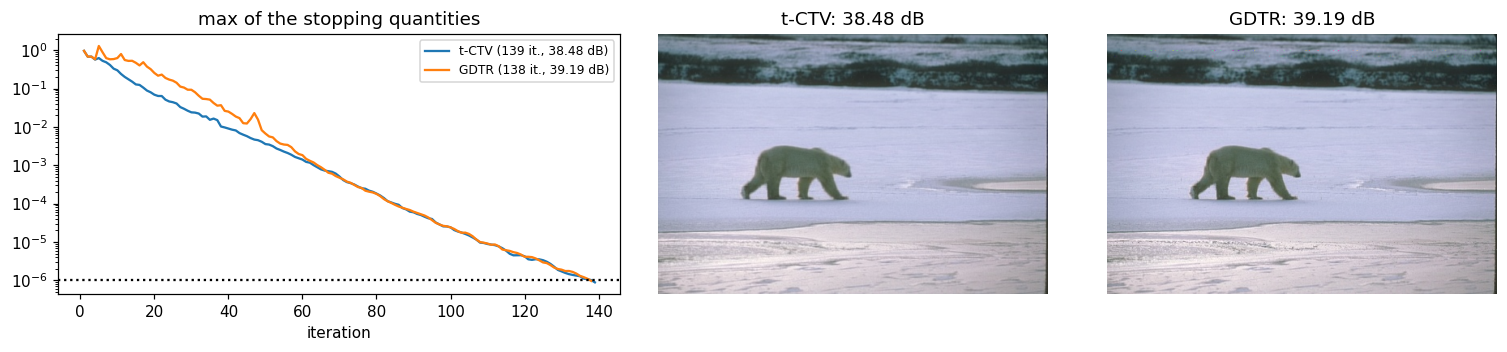

t-CTV(X0) = 171.59, TGTNN(X0) = 98.77  (clean image); t-CTV(X) = 1727.42, TGTNN(X) = 1198.81  (corrupted)


In [10]:
def gconv_job(name):
    kw = dict(tube_L=False, tube_E=False) if name == 't-CTV' else {}
    L, E, h = gdtr(X0n, history=True, **kw)
    return name, h, psnr(L, ref0), L


gconv = run_parallel(gconv_job, ['t-CTV', 'GDTR'])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.3), gridspec_kw={'width_ratios': [1.3, 1, 1]})
for name, h, p, _ in gconv:
    ax[0].semilogy(h.index, h[['dL', 'dE', 'err', 'grad_err']].max(axis=1), label=f'{name} ({len(h)} it., {p:.2f} dB)')
ax[0].axhline(1e-6, color='k', ls=':'); ax[0].set(title='max of the stopping quantities', xlabel='iteration'); ax[0].legend(fontsize=8)
for a, (name, _, p, L) in zip(ax[1:], gconv):
    a.imshow(np.clip(L, 0, 1)); a.set_title(f'{name}: {p:.2f} dB'); a.axis('off')
plt.tight_layout(); plt.show()
print(f't-CTV(X0) = {tctv(ref0):.2f}, TGTNN(X0) = {tgtnn(ref0):.2f}  (clean image); '
      f't-CTV(X) = {tctv(X0n):.2f}, TGTNN(X) = {tgtnn(X0n):.2f}  (corrupted)')

## 6. Additional experiments (supplement §3)

### 6.1 PSNR on the first BSD images (Supp. Fig. 1), plus GDTR in main Tabs. 2–3

Same protocol as main §4.1: 10% tube noise and $\lambda=1/\sqrt{3\max(d_1,d_2)}$. DTR and GDTR use $\gamma_L=3$, $\gamma_E=10^3$. RPCA runs on the $d_1\times(d_2\cdot3)$ unfolding with $\lambda=1/\sqrt{3d_2}$.

The supplement plots the first 50 BSD images. We default to the first `N_SUPP_IMAGES` test images. Its first six images are the examples of notebook 01, with identical noise.

In [11]:
def rpca(M, lam=None, mu=1e-2, rho=1.1, mu_max=1e10, tol=1e-6, max_iter=500):
    """Matrix RPCA (nuclear norm + l1, Candes et al.) with the same ADMM scheme as Algorithm 1."""
    lam = 1.0 / np.sqrt(max(M.shape)) if lam is None else lam
    L, E, N = np.zeros_like(M), np.zeros_like(M), np.zeros_like(M)
    for _ in range(max_iter):
        U, s, Vh = np.linalg.svd(M - E - N / mu, full_matrices=False)
        L_new = (U * np.maximum(s - 1.0 / mu, 0.0)) @ Vh
        K = M - L_new - N / mu
        E_new = np.sign(K) * np.maximum(np.abs(K) - lam / mu, 0.0)
        R = L_new + E_new - M
        N = N + mu * R
        done = max(np.abs(L_new - L).max(), np.abs(E_new - E).max(), np.abs(R).max()) < tol
        L, E, mu = L_new, E_new, min(rho * mu, mu_max)
        if done:
            break
    return L, E


def rpca_unfold(X, **kw):
    L, E = rpca(X.reshape(X.shape[0], -1), **kw)
    return L.reshape(X.shape), E.reshape(X.shape)


METHODS = {'RPCA': (rpca_unfold, {}), 'TRPCA': (dtr, VARIANTS['TRPCA']), 'DTR': (dtr, {}),
           't-CTV': (gdtr, dict(tube_L=False, tube_E=False)), 'GDTR': (gdtr, {})}


def recover_job(job):
    """Worker: run METHODS[job['method']] with extra kwargs job['kw']; returns PSNR, wall time
    (measured while other workers run) and, if job['keep'], the clipped estimate."""
    fn, kw = METHODS[job['method']]
    t0 = time.perf_counter()
    L, _ = fn(job['X'], **{**kw, **job.get('kw', {})})
    out = {k: v for k, v in job.items() if k not in ('X', 'ref', 'kw', 'keep')}
    out.setdefault('label', job['method'])
    out.update(psnr=psnr(L, job['ref']), time=time.perf_counter() - t0)
    if job.get('keep'):
        out['L'] = np.clip(L, 0, 1)
    return out

125 runs in 677 s


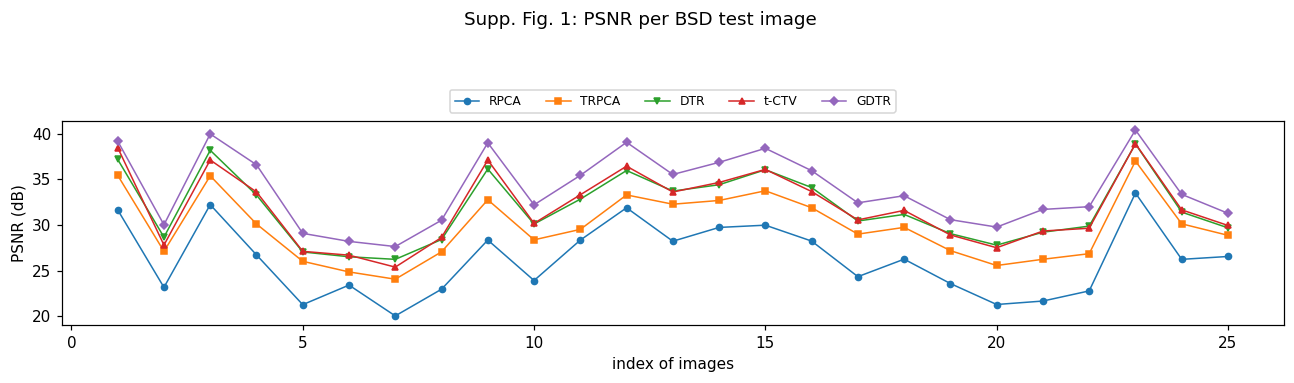

,mean PSNR,std,mean time (s),best on # images,paper BSD(500) mean,paper time (s)
RPCA,26.25,3.86,19.99,0,NaN,NaN
TRPCA,29.81,3.58,37.60,0,28.84,5.13
DTR,31.85,3.76,38.97,0,30.84,6.68
t-CTV,31.92,3.94,100.16,0,31.06,14.93
GDTR,33.94,3.96,113.18,25,33.03,18.26


In [12]:
N_SUPP_IMAGES = 25
rng = np.random.default_rng(SEED)
supp_items = []
for f in TEST_FILES[:N_SUPP_IMAGES]:
    ref = load_image(f)
    supp_items.append((f.stem, ref, tube_corrupt(ref, 0.10, rng)[0]))
jobs = [dict(key=k, idx=i + 1, method=m, X=Xn, ref=ref, keep=i < 3)
        for i, (k, ref, Xn) in enumerate(supp_items) for m in METHODS]

t0 = time.time()
supp_res = run_parallel(recover_job, jobs)
print(f'{len(jobs)} runs in {time.time() - t0:.0f} s')
supp_df = pd.DataFrame(supp_res).drop(columns='L', errors='ignore')
supp_est = {(r['key'], r['method']): r['L'] for r in supp_res if 'L' in r}
P = supp_df.pivot(index='idx', columns='method', values='psnr')[list(METHODS)]

n_rows = int(np.ceil(len(P) / 25))
fig, axes = plt.subplots(n_rows, 1, figsize=(12, 3.3 * n_rows), squeeze=False)
for r, ax in enumerate(axes[:, 0]):
    part = P.iloc[25 * r:25 * (r + 1)]
    for m, mk in zip(METHODS, 'osv^D'):
        ax.plot(part.index, part[m], marker=mk, ms=4, lw=1, label=m)
    ax.set(xlabel='index of images', ylabel='PSNR (dB)')
axes[0, 0].legend(ncol=5, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, 1.18))
plt.suptitle('Supp. Fig. 1: PSNR per BSD test image', y=1.04); plt.tight_layout(); plt.show()

summary_img = pd.DataFrame({'mean PSNR': P.mean(), 'std': P.std(), 'mean time (s)': supp_df.groupby('method').time.mean(),
                            'best on # images': P.idxmax(axis=1).value_counts().reindex(list(METHODS), fill_value=0)})
summary_img['paper BSD(500) mean'] = pd.Series({'TRPCA': 28.84, 'DTR': 30.84, 't-CTV': 31.06, 'GDTR': 33.03})
summary_img['paper time (s)'] = pd.Series({'TRPCA': 5.13, 'DTR': 6.68, 't-CTV': 14.93, 'GDTR': 18.26})
display(summary_img.reindex(list(METHODS)))

Main Tab. 2 with all methods (our six images are not the paper's six; compare the ordering of methods)


,RPCA,TRPCA,DTR,t-CTV,GDTR,paper TRPCA,paper DTR,paper t-CTV,paper GDTR
1: 100007,31.66,35.45,37.19,38.48,39.19,31.05,34.31,34.54,37.44
2: 100039,23.16,27.11,28.67,27.80,30.02,33.95,37.13,37.76,40.32
3: 100099,32.23,35.39,38.19,37.12,39.98,28.25,32.19,33.04,35.92
4: 10081,26.72,30.11,33.28,33.62,36.60,25.49,29.42,30.29,33.60
5: 101027,21.27,26.02,27.04,27.11,29.08,27.12,30.16,29.55,32.22
6: 101084,23.41,24.85,26.52,26.69,28.20,29.54,33.40,33.13,36.61


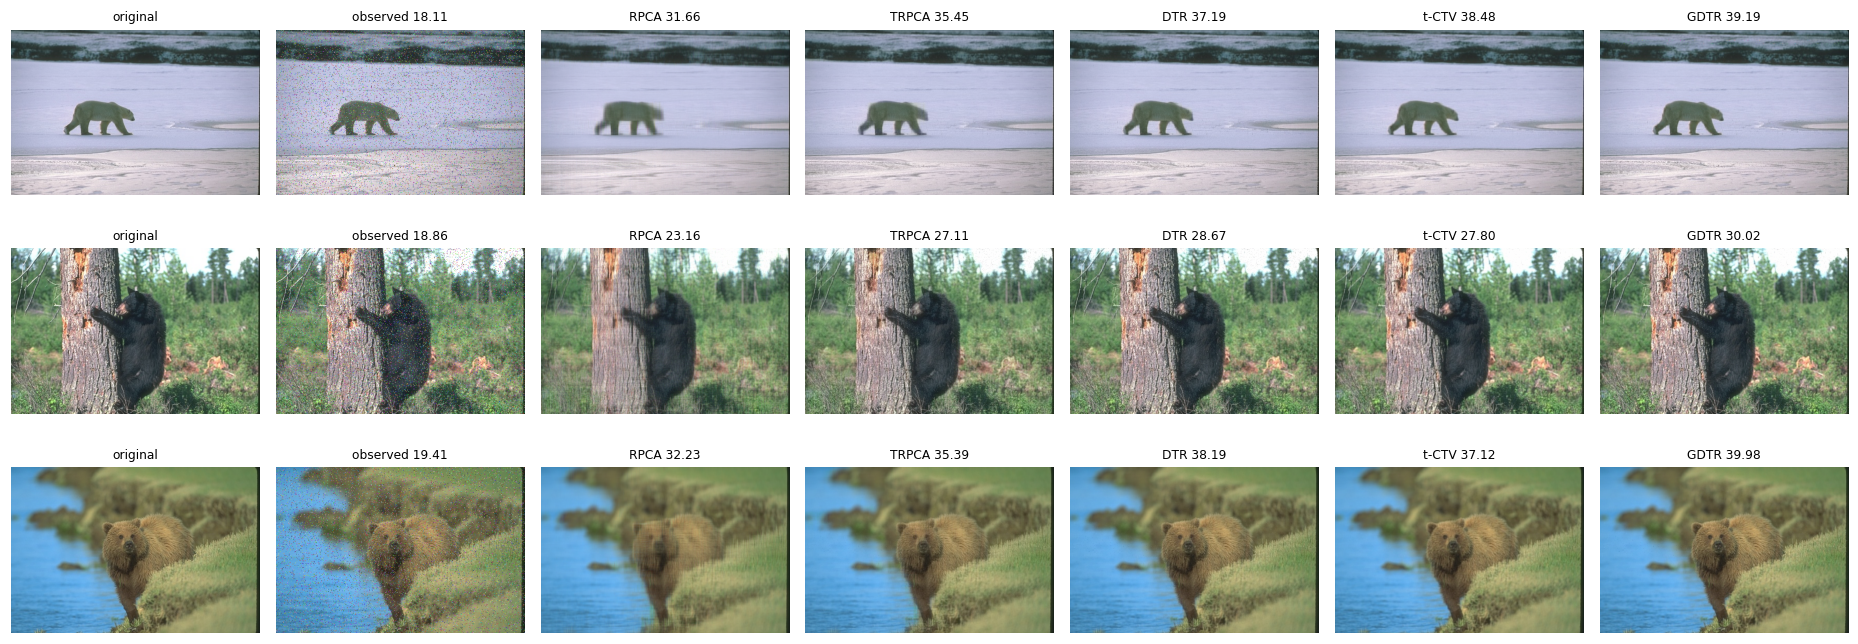

In [13]:
tab2 = P.iloc[:6].copy()
tab2.index = [f'{i}: {k}' for i, k in zip(P.index[:6], [it[0] for it in supp_items[:6]])]
paper2 = pd.DataFrame({'paper TRPCA': [31.05, 33.95, 28.25, 25.49, 27.12, 29.54],
                       'paper DTR': [34.31, 37.13, 32.19, 29.42, 30.16, 33.40],
                       'paper t-CTV': [34.54, 37.76, 33.04, 30.29, 29.55, 33.13],
                       'paper GDTR': [37.44, 40.32, 35.92, 33.60, 32.22, 36.61]}).iloc[:len(tab2)].set_axis(tab2.index)
print('Main Tab. 2 with all methods (our six images are not the paper\'s six; compare the ordering of methods)')
display(pd.concat([tab2, paper2], axis=1))

shown = supp_items[:3]
fig, axes = plt.subplots(len(shown), 2 + len(METHODS), figsize=(17, 2.1 * len(shown)))
for row, (key, ref, Xn) in zip(axes, shown):
    panels = [('original', ref), (f'observed {psnr(Xn, ref):.2f}', Xn)] + \
             [(f'{m} {psnr(supp_est[key, m], ref):.2f}', supp_est[key, m]) for m in METHODS]
    for ax, (title, im) in zip(row, panels):
        ax.imshow(np.clip(im, 0, 1)); ax.set_title(title, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

### 6.2 Video denoising with t-CTV and GDTR (main Tab. 5)

Same videos and noise as notebook 01, §8: the same seed gives identical corrupted tensors. $\Gamma=\{1,2,3\}$.

Notebook 01 showed that DTR with $\gamma_E=10^3$ leaves T2L1 nearly inactive on these videos. We therefore also sweep $\gamma_E$ for GDTR on Akiyo and rerun the other videos with the best value. That value is tuned on test data, so read it as a diagnostic, not a benchmark number. GDTR on a $144\times176\times100$ video needs about 0.7 GB per worker, so this section uses at most 7 workers.

GDTR on Akiyo, PSNR vs gamma_E: {1.0: 37.87, 3.0: 36.44, 10.0: 29.68, 1000.0: 25.4} -> selected 1.0


14 runs in 499 s


,akiyo,claire,container,news,mean,avg time (s)
t-CTV,27.02,25.64,27.20,24.17,26.01,239.38
GDTR,25.40,24.07,25.74,23.23,24.61,233.46
GDTR (gE=1),37.87,38.87,36.01,32.52,36.32,232.65
paper t-CTV,32.24,32.32,31.07,28.38,31.00,80.45
paper GDTR,35.86,37.03,34.56,31.04,34.62,96.18


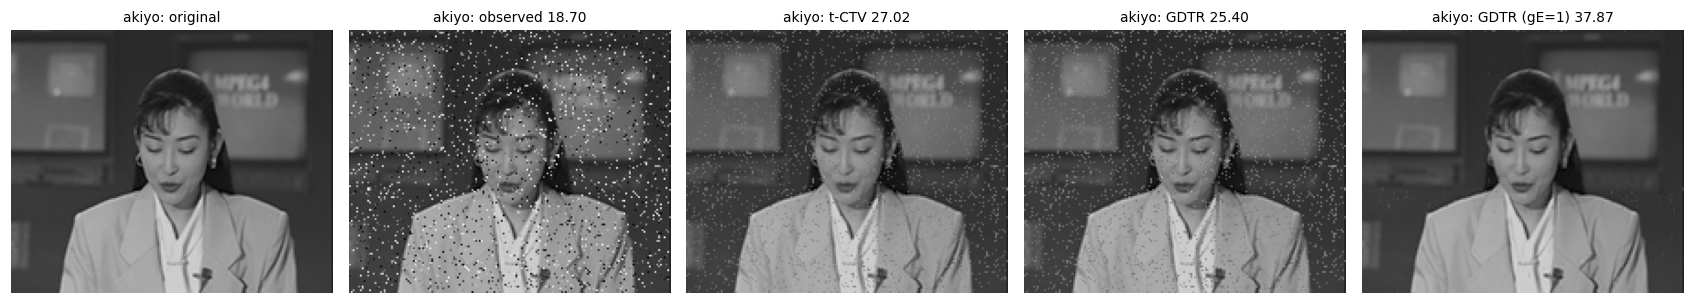

In [14]:
VIDEOS = ('akiyo', 'claire', 'container', 'news')
N_FRAMES = 100
GDTR_GAMMA_E_GRID = (1, 3, 10, 1e3)
rng = np.random.default_rng(SEED + 4)
vid_ref, vid_obs = {}, {}
for v in VIDEOS:
    vid_ref[v] = read_y4m(ensure_yuv(v), N_FRAMES)
    vid_obs[v] = tube_corrupt(vid_ref[v], 0.10, rng)[0]


def vjob(v, method, gamma_E=1e3):
    label = method if gamma_E == 1e3 else f'{method} (gE={gamma_E:g})'
    return dict(key=v, method=method, label=label, gamma_E=gamma_E, X=vid_obs[v], ref=vid_ref[v],
                kw=dict(Gamma=(0, 1, 2), gamma_E=gamma_E), keep=v == 'akiyo')


t0 = time.time()
phase1 = run_parallel(recover_job, [vjob('akiyo', 'GDTR', g) for g in GDTR_GAMMA_E_GRID] +
                      [vjob(v, 't-CTV') for v in VIDEOS[:3]], n_jobs=min(N_JOBS, 7))
sweep = pd.DataFrame([r for r in phase1 if r['method'] == 'GDTR']).set_index('gamma_E').psnr
GDTR_VIDEO_GAMMA_E = float(sweep.idxmax())
print('GDTR on Akiyo, PSNR vs gamma_E:', sweep.round(2).to_dict(), '-> selected', GDTR_VIDEO_GAMMA_E)

phase2_jobs = [vjob('news', 't-CTV')] + [vjob(v, 'GDTR') for v in VIDEOS[1:]]
if GDTR_VIDEO_GAMMA_E != 1e3:
    phase2_jobs += [vjob(v, 'GDTR', GDTR_VIDEO_GAMMA_E) for v in VIDEOS[1:]]
phase2 = run_parallel(recover_job, phase2_jobs, n_jobs=min(N_JOBS, 7))
print(f'{len(phase1) + len(phase2)} runs in {time.time() - t0:.0f} s')

vres = pd.DataFrame(phase1 + phase2).drop(columns='L', errors='ignore')
vest = {r['label']: r['L'] for r in phase1 + phase2 if 'L' in r}
labels = ['t-CTV', 'GDTR'] + ([f'GDTR (gE={GDTR_VIDEO_GAMMA_E:g})'] if GDTR_VIDEO_GAMMA_E != 1e3 else [])
tab5 = vres[vres.label.isin(labels)].pivot(index='label', columns='key', values='psnr').loc[labels, list(VIDEOS)]
tab5['mean'] = tab5.mean(axis=1)
tab5['avg time (s)'] = vres[vres.label.isin(labels)].groupby('label').time.mean()
paper5 = pd.DataFrame([[32.24, 32.32, 31.07, 28.38], [35.86, 37.03, 34.56, 31.04]], index=['paper t-CTV', 'paper GDTR'],
                      columns=list(VIDEOS))
paper5['mean'] = paper5.mean(axis=1)
paper5['avg time (s)'] = [80.45, 96.18]
display(pd.concat([tab5, paper5]))

fr = N_FRAMES // 2
fig, ax = plt.subplots(1, 2 + len(labels), figsize=(3.1 * (2 + len(labels)), 2.8))
for a, (title, im) in zip(ax, [('original', vid_ref['akiyo']), ('observed', vid_obs['akiyo'])] + [(lb, vest[lb]) for lb in labels]):
    p = '' if title == 'original' else f' {psnr(im, vid_ref["akiyo"]):.2f}'
    a.imshow(im[:, :, fr], vmin=0, vmax=1); a.set_title(f'akiyo: {title}{p}', fontsize=9); a.axis('off')
plt.tight_layout(); plt.show()

## 7. Summary: paper vs. this implementation

In [15]:
summary = pd.DataFrame({
    f'images ours ({N_SUPP_IMAGES} BSD test)': P[['TRPCA', 'DTR', 't-CTV', 'GDTR']].mean(),
    'images paper (BSD 500)': pd.Series({'TRPCA': 28.84, 'DTR': 30.84, 't-CTV': 31.06, 'GDTR': 33.03}),
    'videos ours (mean of 4)': tab5['mean'],
    'videos paper (mean of 4)': pd.Series({'t-CTV': paper5.loc['paper t-CTV', 'mean'], 'GDTR': paper5.loc['paper GDTR', 'mean']}),
}).reindex(['TRPCA', 'DTR', 't-CTV'] + labels[1:])
print('Mean PSNR (dB). TRPCA / DTR video results are in notebook 01, section 9.')
display(summary)

Mean PSNR (dB). TRPCA / DTR video results are in notebook 01, section 9.


,images ours (25 BSD test),images paper (BSD 500),videos ours (mean of 4),videos paper (mean of 4)
TRPCA,29.81,28.84,NaN,NaN
DTR,31.85,30.84,NaN,NaN
t-CTV,31.92,31.06,26.01,31.00
GDTR,33.94,33.03,24.61,34.62
GDTR (gE=1),NaN,NaN,36.32,NaN


### Observations from the saved run (default settings)

**Theory: confirmed numerically**
- **Theorem 1.** No perturbation or Powell restart beats the closed-form T2NN proximal operator (all differences $\ge0$).
- **The ordering assumption $w_1\le\dots\le w_d$ is necessary.** With decreasing weights, the closed form (objective 7.00) is beaten by 4.56. The structure function $f_L$ always produces nondecreasing weights.
- **Lemma 2.** $\max_t\|\mathcal N^t\|_F=14.3$, below both the paper's bound $\lambda d_1d_2d_3=12194$ and the tighter $\lambda\sqrt{d_1d_2d_3}=17.9$. The weights stay in $(0,1]$.
- **Lemma 3 and Theorem 2.** The iterates are bounded, and all three residuals decay geometrically to about $3\times10^{-9}$ by iteration 233, with uncapped $\mu$.
- **A side effect of the weights.** At convergence on this image, $\min_{ij}W_{ij}\approx0.98$, so T2L1 is almost inactive. Meanwhile $\min_l w_l\approx0.015$, so the dominant singular tubes are barely shrunk. Both match notebook 01.

**GDTR (Algorithm 2)**
- The gradient operator, its adjoint and the FFT diagonalisation behind Eq. (27) are verified to machine precision.

**Color images (Supp. Fig. 1, main Tabs. 2–3): reproduced**
- GDTR is the best method on **25 / 25** test images.
- Mean PSNR: GDTR 33.94, t-CTV 31.92, DTR 31.85, TRPCA 29.81, RPCA 26.25.
- The gains match the paper: GDTR over t-CTV is +2.0 dB (paper +1.97), and DTR over TRPCA is +2.0 dB (paper +2.0).
- The run time of GDTR is about 2.9× that of DTR (paper: 2.7×).

**Video (main Tab. 5): not reproduced with $\gamma_E=10^3$**
- GDTR (24.61 dB mean) is below t-CTV (26.01), and both are far below the paper's 34.62 / 31.00.
- With $\gamma_E=1$, selected on Akiyo, GDTR reaches **36.32 dB**, above the paper's value. This is the same $\gamma_E$ issue found for DTR in notebook 01.
- t-CTV has no γ parameters, yet it is still about 5 dB below the paper. That again points to an unreported difference in the video protocol.